# E_field_identifications

See the repository README for inputs, environment variables, and execution status. Except where listed in `REVISION_VALIDATION.md`, saved outputs are historical and were not rerun for this revision. The two A320 bias algorithms are instructor-supplied; assistance and supplementary analysis are disclosed in the report appendix.

In [1]:
from pathlib import Path
import os
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
%matplotlib inline
ROOT = Path.cwd().parent
DATA = ROOT / 'data'
OUT = ROOT / 'results'
OUT.mkdir(exist_ok=True)
RAW = Path(os.environ.get('ASTRO320W_DATA', str(ROOT / 'raw')))
BIAS = Path(os.environ.get('ASTRO320W_BIAS', str(ROOT / 'raw' / 'Bias_Frames')))


q [499. 499.]
matches 28 flip -1 scale 0.5757718843000719 rms 1.3180548752029777
fieldmatches 27 rms 0.8247257951935872
pair survey [[500.38307139 499.1619586 ]
 [487.37362294 499.13103465]] sky <SkyCoord (ICRS): (ra, dec) in deg
    [(249.68577691, 48.92837717), (249.69765776, 48.92835813)]> sep 28.100744712558445 PA 90.13524172212975


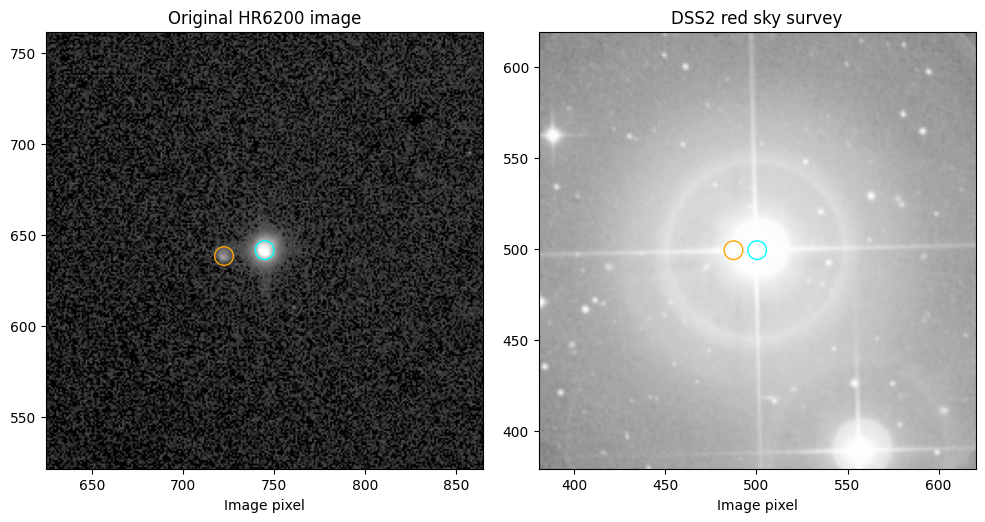

In [2]:
import os
os.environ['MPLCONFIGDIR']='/private/tmp/astro320-mpl'
import numpy as np
from astropy.io import fits
from astropy.wcs import WCS
from scipy.ndimage import gaussian_filter,maximum_filter
from scipy.spatial import cKDTree
import matplotlib
import matplotlib.pyplot as plt
src=fits.getdata(RAW/'Exercise E/EXERCISE E/CCD Image 9.fit').astype(float)
ref,h=fits.getdata(DATA/'hr6200_survey.fits',header=True); ref=ref.astype(float)
def detect(a,n):
 s=gaussian_filter(a,1.5); bg=gaussian_filter(a,20); d=s-bg
 y,x=np.where((d==maximum_filter(d,15))&(d>np.std(d)*.25))
 k=np.argsort(d[y,x])[::-1]; pts=np.array([x[k],y[k]]).T
 return pts[(pts[:,0]>15)&(pts[:,1]>15)&(pts[:,0]<a.shape[1]-15)&(pts[:,1]<a.shape[0]-15)][:n]
a=detect(src,65); b=detect(ref,100)
p=np.array([744.,642.]); q=np.array([499.,499.]); print('q',q)
tree=cKDTree(b); best=None
for flip in [1,-1]:
 av=(a-p)*[1,flip]
 for v in av:
  if np.linalg.norm(v)<60:continue
  for w in b-q:
   if np.linalg.norm(w)<35:continue
   z=complex(*w)/complex(*v)
   if not .45<abs(z)<.72:continue
   m=np.array([[z.real,-z.imag],[z.imag,z.real]])
   pred=av@m.T+q; ds,ix=tree.query(pred); good=ds<4
   score=good.sum()
   if best is None or score>best[0]:best=(score,flip,m,good,ix,ds)
score,flip,m,good,ix,ds=best
print('matches',score,'flip',flip,'scale',np.linalg.norm(m[:,0]),'rms',np.sqrt(np.mean(ds[good]**2)))
# affine fit using field matches, excluding central saturated star
sel=good&(np.linalg.norm(a-p,axis=1)>40)
X=np.c_[a[sel],np.ones(sel.sum())]; coef=np.linalg.lstsq(X,b[ix[sel]],rcond=None)[0]
for k in range(3):
 pred=np.c_[a,np.ones(len(a))]@coef; ds,ix=tree.query(pred); sel=(ds<3)&(np.linalg.norm(a-p,axis=1)>40);coef=np.linalg.lstsq(np.c_[a[sel],np.ones(sel.sum())],b[ix[sel]],rcond=None)[0]
print('fieldmatches',sel.sum(),'rms',np.sqrt(np.mean(ds[sel]**2)))
# convert supplied ImageJ to native FITS array
pair=np.array([[744.8426763467418,1528-886.4694746576968],[722.5199023861171,1528-889.7116129032258]])
pr=np.c_[pair,np.ones(2)]@coef
wcs=WCS(h); sky=wcs.pixel_to_world(pr[:,0],pr[:,1]);print('pair survey',pr,'sky',sky,'sep',sky[0].separation(sky[1]).arcsec,'PA',sky[0].position_angle(sky[1]).deg)
np.savez(OUT/'hr6200_match.npz',coef=coef,a=a,b=b,sel=sel,ix=ix,pair=pair,pr=pr)
fig,axs=plt.subplots(1,2,figsize=(10,5))
for ax,im,pts,title in zip(axs,[src,ref],[pair,pr],['Original HR6200 image','DSS2 red sky survey']):
 ax.imshow(np.arcsinh(np.maximum(im-np.median(im),0)/max(np.std(im)*.05,1)),origin='lower',cmap='gray');ax.scatter(pts[:,0],pts[:,1],s=180,facecolors='none',edgecolors=['cyan','orange']);ax.set_xlim(pts[0,0]-120,pts[0,0]+120);ax.set_ylim(pts[0,1]-120,pts[0,1]+120);ax.set_title(title);ax.set_xlabel('Image pixel');
fig.tight_layout();fig.savefig(OUT/'HR6200_survey_check.png',dpi=180)


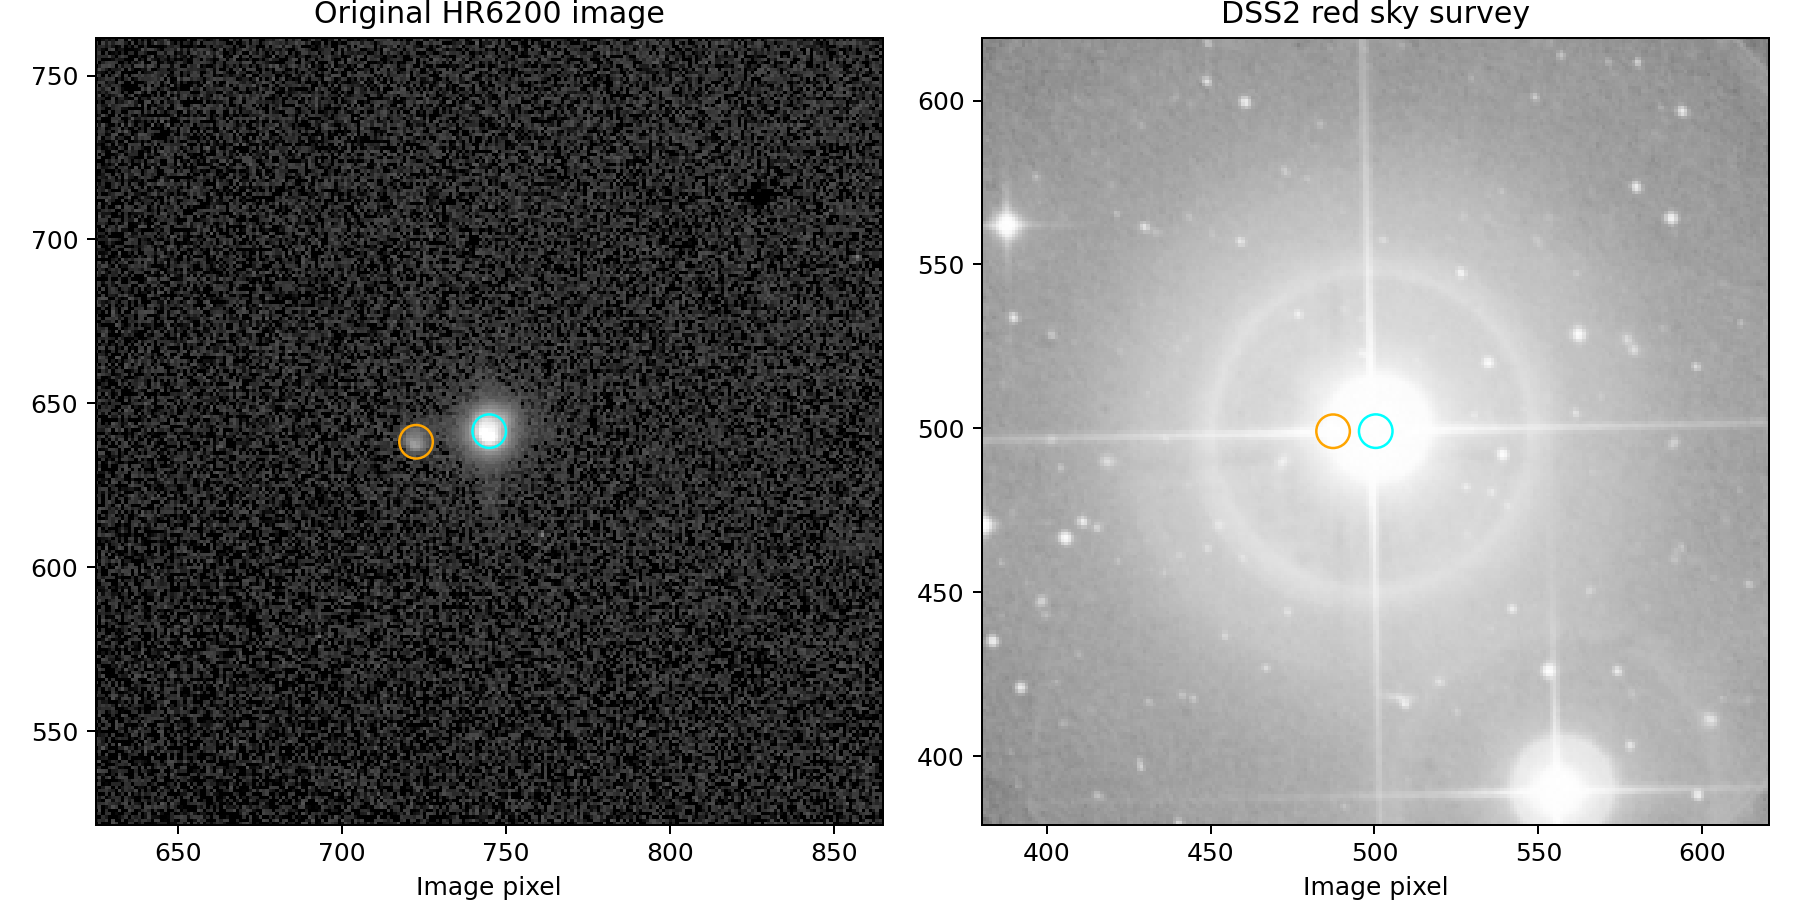

In [3]:
display(Image(filename=str(OUT/'HR6200_survey_check.png')))

q [499. 499.]
matches 33 flip -1 scale 0.5779902825311832 rms 1.8883778533170088
fieldmatches 33 rms 0.5954683353245349
pair survey [[500.23324228 498.23873774]
 [490.89690807 402.80878498]] sky <SkyCoord (ICRS): (ra, dec) in deg
    [(303.86690025, 47.71376323), (303.87521806, 47.65650454)]> sep 207.1146583847632 PA 174.41146944021898


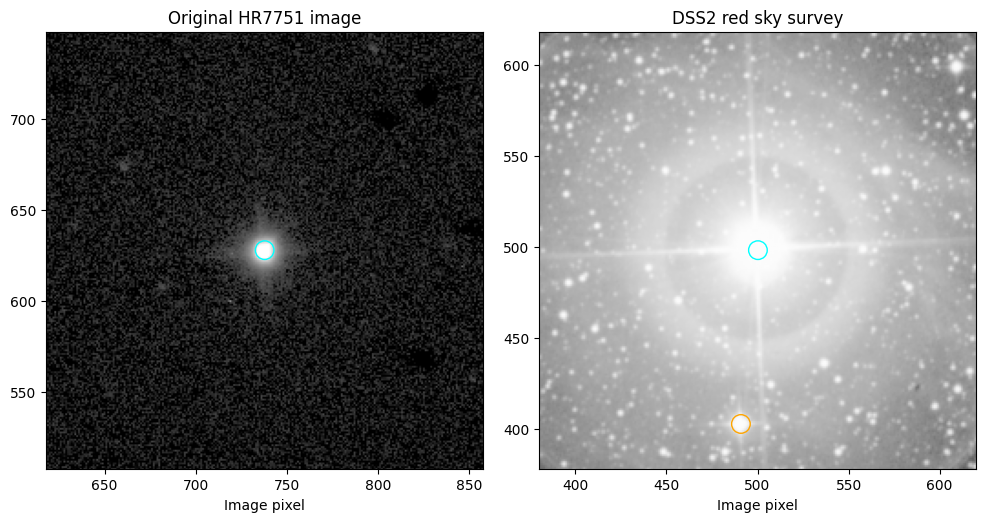

In [4]:
import os
os.environ['MPLCONFIGDIR']='/private/tmp/astro320-mpl'
import numpy as np
from astropy.io import fits
from astropy.wcs import WCS
from scipy.ndimage import gaussian_filter,maximum_filter
from scipy.spatial import cKDTree
import matplotlib
import matplotlib.pyplot as plt
src=fits.getdata(RAW/'Exercise E/EXERCISE E/CCD Image 21.fit').astype(float)
ref,h=fits.getdata(DATA/'hr7751_survey.fits',header=True); ref=ref.astype(float)
def detect(a,n):
 s=gaussian_filter(a,1.5); bg=gaussian_filter(a,20); d=s-bg
 y,x=np.where((d==maximum_filter(d,15))&(d>np.std(d)*.25))
 k=np.argsort(d[y,x])[::-1]; pts=np.array([x[k],y[k]]).T
 return pts[(pts[:,0]>15)&(pts[:,1]>15)&(pts[:,0]<a.shape[1]-15)&(pts[:,1]<a.shape[0]-15)][:n]
a=detect(src,65); b=detect(ref,100)
p=np.array([738.,628.]); q=np.array([499.,499.]); print('q',q)
tree=cKDTree(b); best=None
for flip in [1,-1]:
 av=(a-p)*[1,flip]
 for v in av:
  if np.linalg.norm(v)<60:continue
  for w in b-q:
   if np.linalg.norm(w)<35:continue
   z=complex(*w)/complex(*v)
   if not .45<abs(z)<.72:continue
   m=np.array([[z.real,-z.imag],[z.imag,z.real]])
   pred=av@m.T+q; ds,ix=tree.query(pred); good=ds<4
   score=good.sum()
   if best is None or score>best[0]:best=(score,flip,m,good,ix,ds)
score,flip,m,good,ix,ds=best
print('matches',score,'flip',flip,'scale',np.linalg.norm(m[:,0]),'rms',np.sqrt(np.mean(ds[good]**2)))
# affine fit using field matches, excluding central saturated star
sel=good&(np.linalg.norm(a-p,axis=1)>40)
X=np.c_[a[sel],np.ones(sel.sum())]; coef=np.linalg.lstsq(X,b[ix[sel]],rcond=None)[0]
for k in range(3):
 pred=np.c_[a,np.ones(len(a))]@coef; ds,ix=tree.query(pred); sel=(ds<3)&(np.linalg.norm(a-p,axis=1)>40);coef=np.linalg.lstsq(np.c_[a[sel],np.ones(sel.sum())],b[ix[sel]],rcond=None)[0]
print('fieldmatches',sel.sum(),'rms',np.sqrt(np.mean(ds[sel]**2)))
# convert supplied ImageJ to native FITS array
pair=np.array([[737.9333475163991,1528-900.0437162689259],[715.9955944763756,1528-735.0378784335512]])
pr=np.c_[pair,np.ones(2)]@coef
wcs=WCS(h); sky=wcs.pixel_to_world(pr[:,0],pr[:,1]);print('pair survey',pr,'sky',sky,'sep',sky[0].separation(sky[1]).arcsec,'PA',sky[0].position_angle(sky[1]).deg)
np.savez(OUT/'hr7751_match.npz',coef=coef,a=a,b=b,sel=sel,ix=ix,pair=pair,pr=pr)
fig,axs=plt.subplots(1,2,figsize=(10,5))
for ax,im,pts,title in zip(axs,[src,ref],[pair,pr],['Original HR7751 image','DSS2 red sky survey']):
 ax.imshow(np.arcsinh(np.maximum(im-np.median(im),0)/max(np.std(im)*.05,1)),origin='lower',cmap='gray');ax.scatter(pts[:,0],pts[:,1],s=180,facecolors='none',edgecolors=['cyan','orange']);ax.set_xlim(pts[0,0]-120,pts[0,0]+120);ax.set_ylim(pts[0,1]-120,pts[0,1]+120);ax.set_title(title);ax.set_xlabel('Image pixel');
fig.tight_layout();fig.savefig(OUT/'HR7751_survey_check.png',dpi=180)


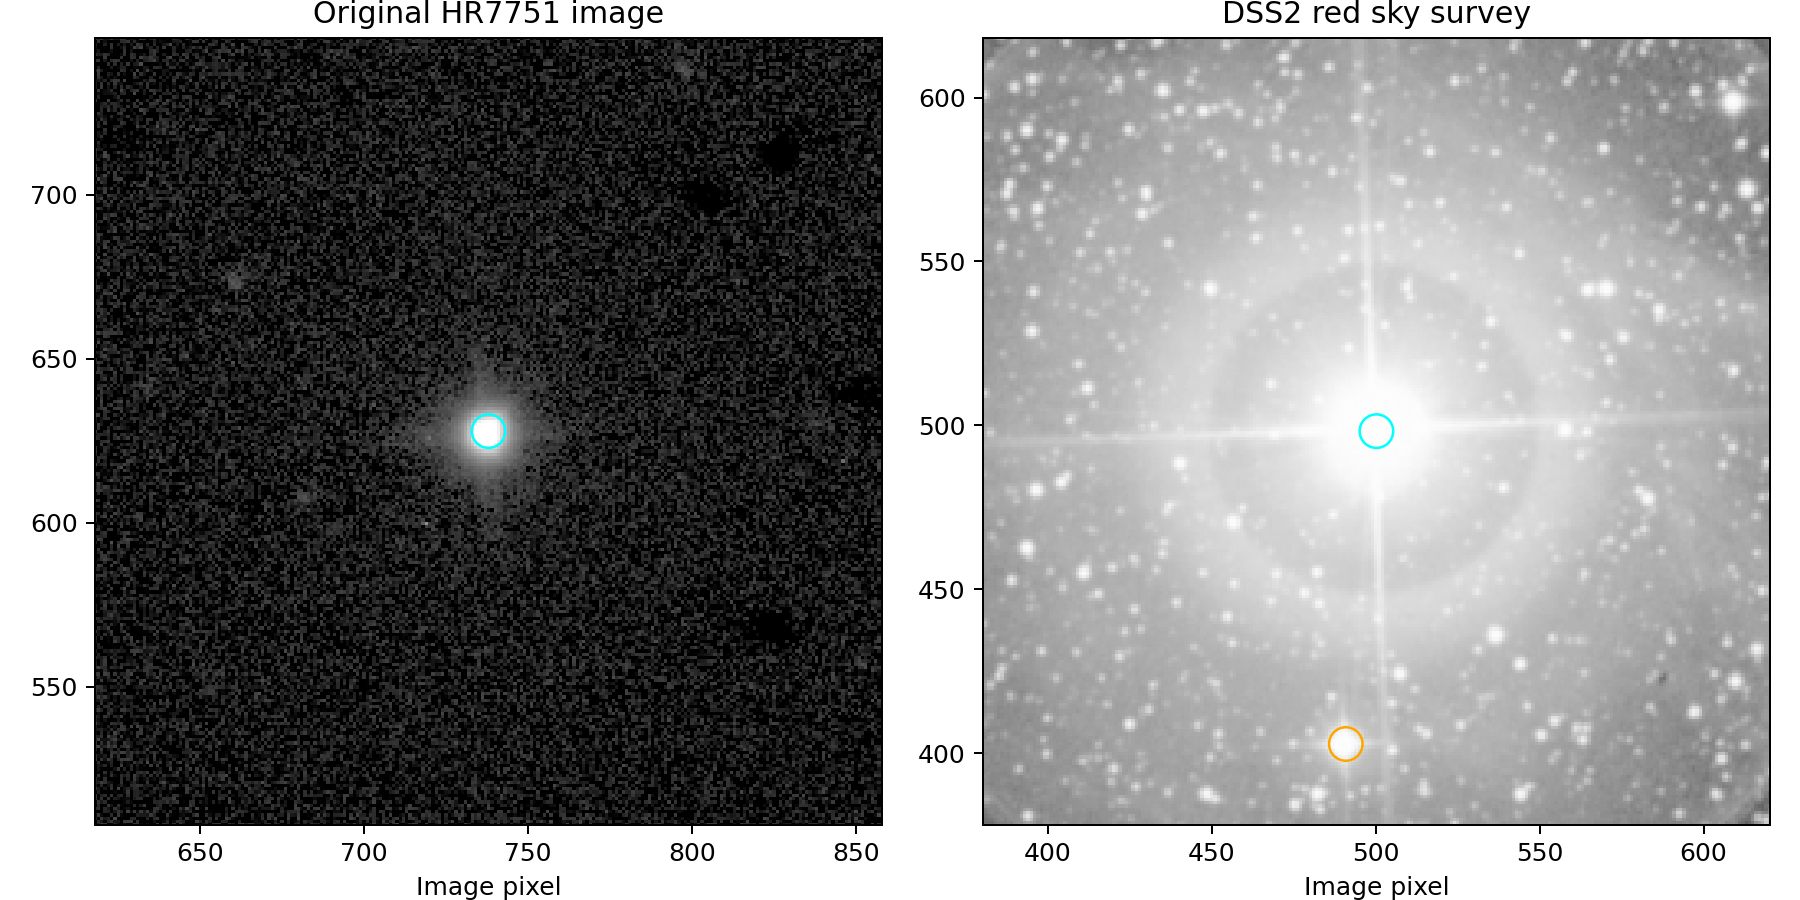

In [5]:
display(Image(filename=str(OUT/'HR7751_survey_check.png')))

q [498 502]
matches 11 flip -1 scale 0.578478422981341 rms 2.780673594219415
fieldmatches 13 rms 0.6268616045164365
pair survey [[499.14539588 498.33572518]
 [503.49243657 484.34889317]] sky <SkyCoord (ICRS): (ra, dec) in deg
    [(347.38095175, 8.67677143), (347.37831337, 8.66837925)]> sep 31.63733866530635 PA 197.26498215124923


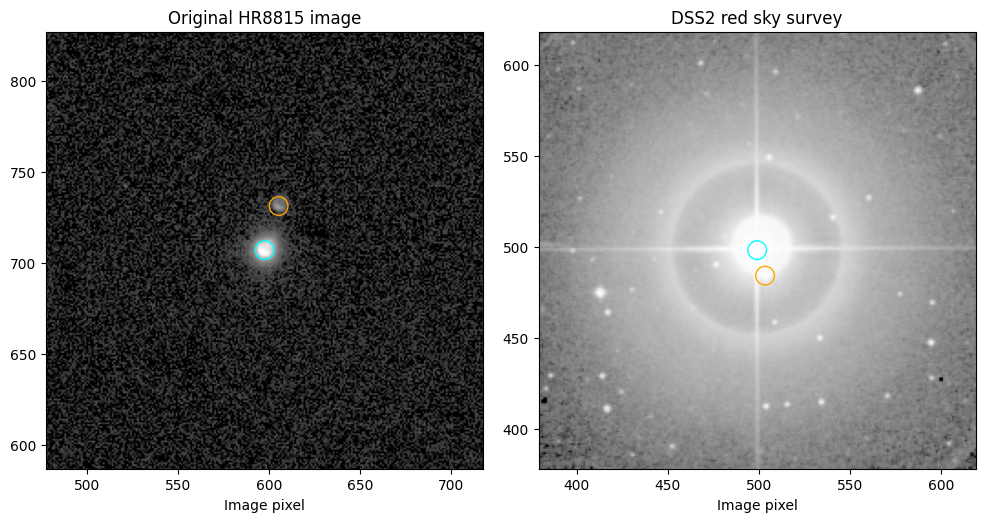

In [6]:
import os
os.environ['MPLCONFIGDIR']='/private/tmp/astro320-mpl'
import numpy as np
from astropy.io import fits
from astropy.wcs import WCS
from scipy.ndimage import gaussian_filter,maximum_filter
from scipy.spatial import cKDTree
import matplotlib
import matplotlib.pyplot as plt
src=fits.getdata(RAW/'Exercise E/EXERCISE E/CCD Image 33.fit').astype(float)
ref,h=fits.getdata(DATA/'hr8815_survey.fits',header=True); ref=ref.astype(float)
def detect(a,n):
 s=gaussian_filter(a,1.5); bg=gaussian_filter(a,20); d=s-bg
 y,x=np.where((d==maximum_filter(d,15))&(d>np.std(d)*.25))
 k=np.argsort(d[y,x])[::-1]; pts=np.array([x[k],y[k]]).T
 return pts[(pts[:,0]>15)&(pts[:,1]>15)&(pts[:,0]<a.shape[1]-15)&(pts[:,1]<a.shape[0]-15)][:n]
a=detect(src,65); b=detect(ref,100)
p=np.array([597.,707.]); q=b[np.argmin(np.linalg.norm(b-[500,500],axis=1))]; print('q',q)
tree=cKDTree(b); best=None
for flip in [1,-1]:
 av=(a-p)*[1,flip]
 for v in av:
  if np.linalg.norm(v)<60:continue
  for w in b-q:
   if np.linalg.norm(w)<35:continue
   z=complex(*w)/complex(*v)
   if not .45<abs(z)<.72:continue
   m=np.array([[z.real,-z.imag],[z.imag,z.real]])
   pred=av@m.T+q; ds,ix=tree.query(pred); good=ds<4
   score=good.sum()
   if best is None or score>best[0]:best=(score,flip,m,good,ix,ds)
score,flip,m,good,ix,ds=best
print('matches',score,'flip',flip,'scale',np.linalg.norm(m[:,0]),'rms',np.sqrt(np.mean(ds[good]**2)))
# affine fit using field matches, excluding central saturated star
sel=good&(np.linalg.norm(a-p,axis=1)>40)
X=np.c_[a[sel],np.ones(sel.sum())]; coef=np.linalg.lstsq(X,b[ix[sel]],rcond=None)[0]
for k in range(3):
 pred=np.c_[a,np.ones(len(a))]@coef; ds,ix=tree.query(pred); sel=(ds<3)&(np.linalg.norm(a-p,axis=1)>40);coef=np.linalg.lstsq(np.c_[a[sel],np.ones(sel.sum())],b[ix[sel]],rcond=None)[0]
print('fieldmatches',sel.sum(),'rms',np.sqrt(np.mean(ds[sel]**2)))
# convert supplied ImageJ to native FITS array
pair=np.array([[597.4132545210787,1528-821.0777533442913],[605.0864859442228,1528-796.8418304668305]])
pr=np.c_[pair,np.ones(2)]@coef
wcs=WCS(h); sky=wcs.pixel_to_world(pr[:,0],pr[:,1]);print('pair survey',pr,'sky',sky,'sep',sky[0].separation(sky[1]).arcsec,'PA',sky[0].position_angle(sky[1]).deg)
np.savez(OUT/'hr8815_match.npz',coef=coef,a=a,b=b,sel=sel,ix=ix,pair=pair,pr=pr)
fig,axs=plt.subplots(1,2,figsize=(10,5))
for ax,im,pts,title in zip(axs,[src,ref],[pair,pr],['Original HR8815 image','DSS2 red sky survey']):
 ax.imshow(np.arcsinh(np.maximum(im-np.median(im),0)/max(np.std(im)*.05,1)),origin='lower',cmap='gray');ax.scatter(pts[:,0],pts[:,1],s=180,facecolors='none',edgecolors=['cyan','orange']);ax.set_xlim(pts[0,0]-120,pts[0,0]+120);ax.set_ylim(pts[0,1]-120,pts[0,1]+120);ax.set_title(title);ax.set_xlabel('Image pixel');
fig.tight_layout();fig.savefig(OUT/'HR8815_survey_check.png',dpi=180)


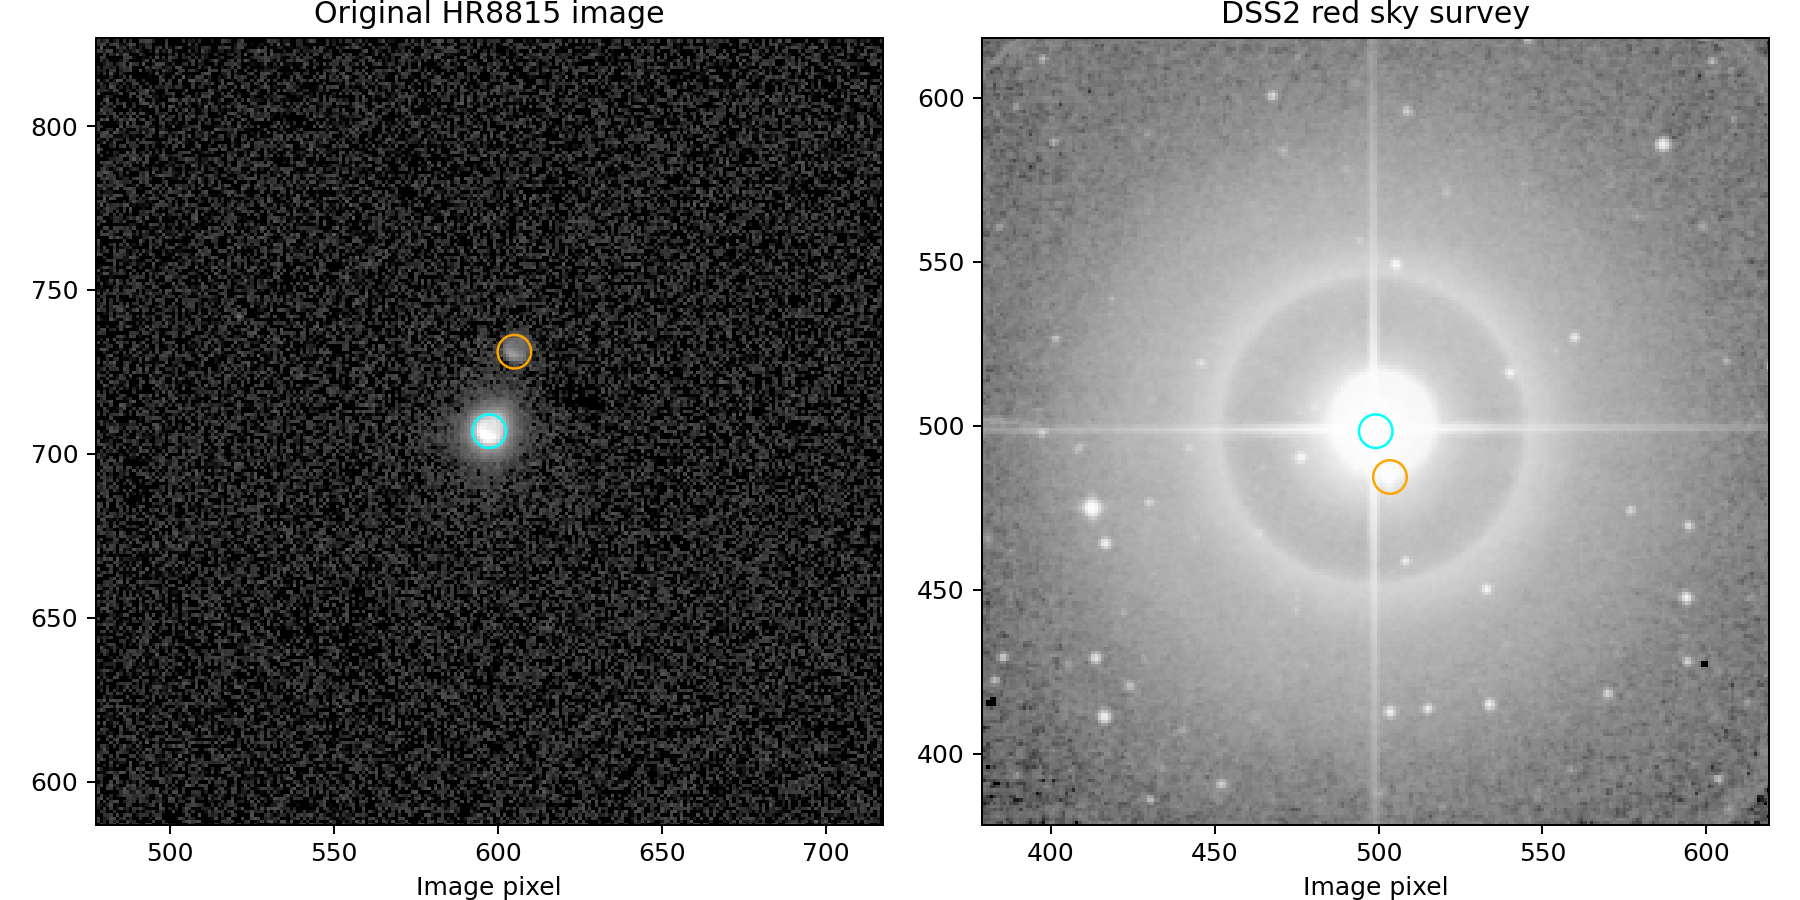

In [7]:
display(Image(filename=str(OUT/'HR8815_survey_check.png')))

q [499. 499.]
matches 22 flip -1 scale 0.5766048148468166 rms 1.2620966124734923
fieldmatches 22 rms 0.5639025611837309
pair survey [[498.60397279 499.90054074]
 [478.30656858 375.29824351]] sky <SkyCoord (ICRS): (ra, dec) in deg
    [(288.13875019, 67.66184633), (288.17068952, 67.58708105)]> sep 272.690826760574 PA 170.7485036176187


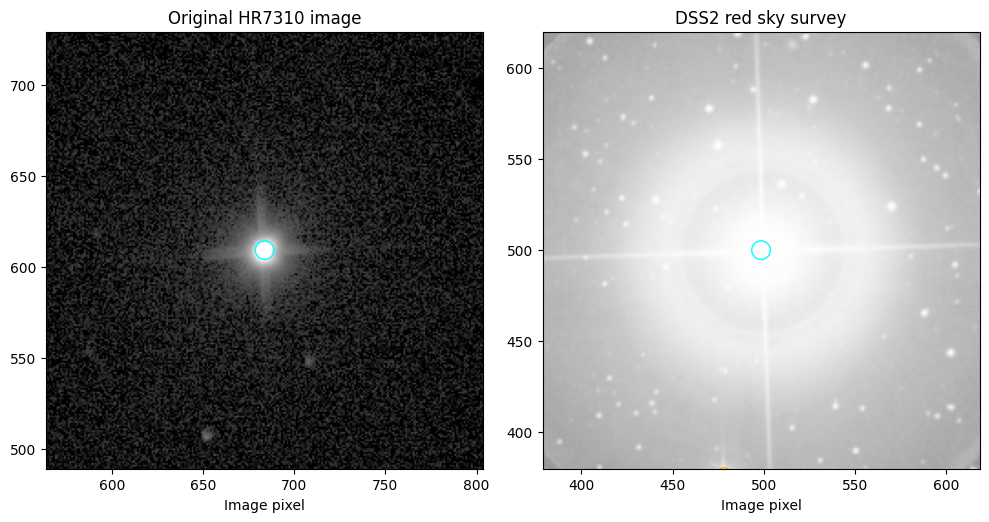

In [8]:
import os
os.environ['MPLCONFIGDIR']='/private/tmp/astro320-mpl'
import numpy as np
from astropy.io import fits
from astropy.wcs import WCS
from scipy.ndimage import gaussian_filter,maximum_filter
from scipy.spatial import cKDTree
import matplotlib
import matplotlib.pyplot as plt
src=fits.getdata(RAW/'Exercise E/EXERCISE E/CCD Image 18.fit').astype(float)
ref,h=fits.getdata(DATA/'hr7310_survey.fits',header=True); ref=ref.astype(float)
def detect(a,n):
 s=gaussian_filter(a,1.5); bg=gaussian_filter(a,20); d=s-bg
 y,x=np.where((d==maximum_filter(d,15))&(d>np.std(d)*.25))
 k=np.argsort(d[y,x])[::-1]; pts=np.array([x[k],y[k]]).T
 return pts[(pts[:,0]>15)&(pts[:,1]>15)&(pts[:,0]<a.shape[1]-15)&(pts[:,1]<a.shape[0]-15)][:n]
a=detect(src,65); b=detect(ref,100)
p=np.array([684.,609.]); q=np.array([499.,499.]); print('q',q)
tree=cKDTree(b); best=None
for flip in [1,-1]:
 av=(a-p)*[1,flip]
 for v in av:
  if np.linalg.norm(v)<60:continue
  for w in b-q:
   if np.linalg.norm(w)<35:continue
   z=complex(*w)/complex(*v)
   if not .45<abs(z)<.72:continue
   m=np.array([[z.real,-z.imag],[z.imag,z.real]])
   pred=av@m.T+q; ds,ix=tree.query(pred); good=ds<4
   score=good.sum()
   if best is None or score>best[0]:best=(score,flip,m,good,ix,ds)
score,flip,m,good,ix,ds=best
print('matches',score,'flip',flip,'scale',np.linalg.norm(m[:,0]),'rms',np.sqrt(np.mean(ds[good]**2)))
# affine fit using field matches, excluding central saturated star
sel=good&(np.linalg.norm(a-p,axis=1)>40)
X=np.c_[a[sel],np.ones(sel.sum())]; coef=np.linalg.lstsq(X,b[ix[sel]],rcond=None)[0]
for k in range(3):
 pred=np.c_[a,np.ones(len(a))]@coef; ds,ix=tree.query(pred); sel=(ds<3)&(np.linalg.norm(a-p,axis=1)>40);coef=np.linalg.lstsq(np.c_[a[sel],np.ones(sel.sum())],b[ix[sel]],rcond=None)[0]
print('fieldmatches',sel.sum(),'rms',np.sqrt(np.mean(ds[sel]**2)))
# convert supplied ImageJ to native FITS array
pair=np.array([[683.659,1528-918.792],[631.266,1528-706.026]])
pr=np.c_[pair,np.ones(2)]@coef
wcs=WCS(h); sky=wcs.pixel_to_world(pr[:,0],pr[:,1]);print('pair survey',pr,'sky',sky,'sep',sky[0].separation(sky[1]).arcsec,'PA',sky[0].position_angle(sky[1]).deg)
np.savez(OUT/'hr7310_match.npz',coef=coef,a=a,b=b,sel=sel,ix=ix,pair=pair,pr=pr)
fig,axs=plt.subplots(1,2,figsize=(10,5))
for ax,im,pts,title in zip(axs,[src,ref],[pair,pr],['Original HR7310 image','DSS2 red sky survey']):
 ax.imshow(np.arcsinh(np.maximum(im-np.median(im),0)/max(np.std(im)*.05,1)),origin='lower',cmap='gray');ax.scatter(pts[:,0],pts[:,1],s=180,facecolors='none',edgecolors=['cyan','orange']);ax.set_xlim(pts[0,0]-120,pts[0,0]+120);ax.set_ylim(pts[0,1]-120,pts[0,1]+120);ax.set_title(title);ax.set_xlabel('Image pixel');
fig.tight_layout();fig.savefig(OUT/'HR7310_survey_check.png',dpi=180)


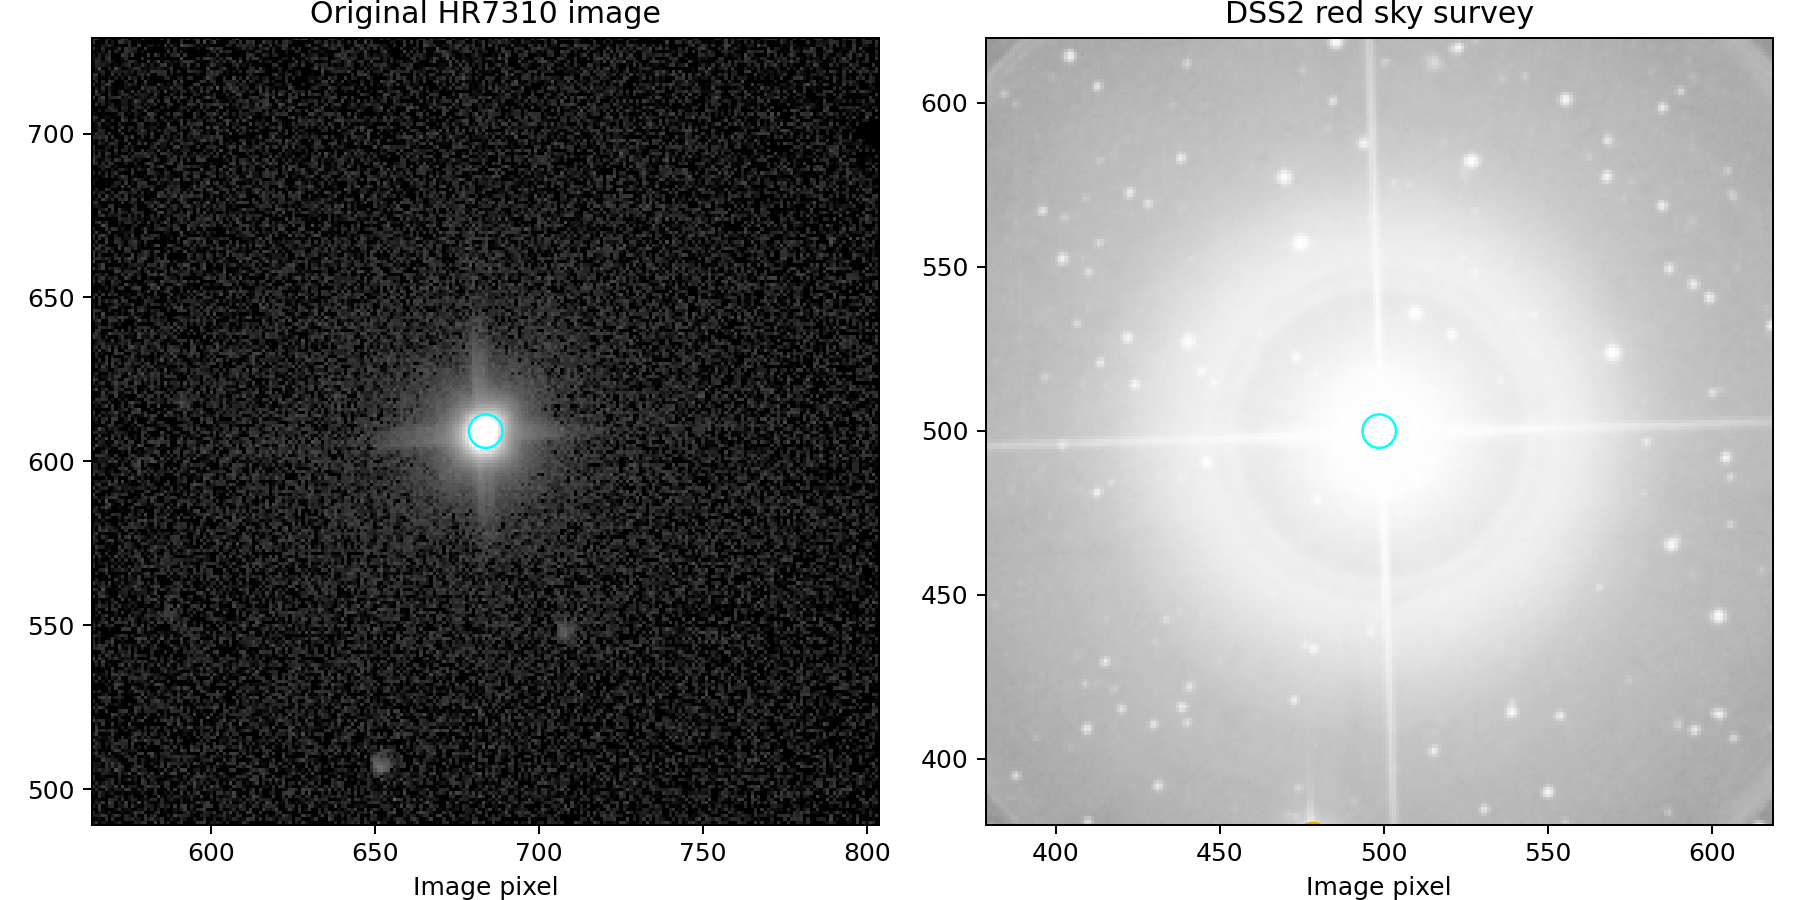

In [9]:
display(Image(filename=str(OUT/'HR7310_survey_check.png')))